# Phase 1: Layer A synthetic population

Builds a population of agents from 2021 Census tables for NSW using iterative proportional fitting (IPF), then checks the agents against those tables.

The census tables are produced by `python -m src.population.census_gcp` (see the README). If they are missing, this notebook falls back to the fake test tables and labels every chart as fake.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from src.population.schema import CORE_ATTRIBUTES
from src.population.tables import load_constraints
from src.population.ipf import ipf
from src.population.sample import sample_agents
from src.population import validate

REAL = ROOT / 'data' / 'processed' / 'tables'
TABLES_DIR = REAL if any(REAL.glob('*.csv')) else ROOT / 'data' / 'sample_fake'
SOURCE_LABEL = 'FAKE test tables (not census)' if 'fake' in TABLES_DIR.name else 'Census 2021'
N_AGENTS = 2000
print('Using tables from:', TABLES_DIR.relative_to(ROOT), '|', SOURCE_LABEL)

Using tables from: data\processed\tables | Census 2021


## 1. Load the tables
Each table becomes a constraint the population must match.

In [2]:
constraints = load_constraints(TABLES_DIR)
for name, c in constraints.items():
    print(f'{name:26s} {" x ".join(c.dims):32s} {c.target.size} cells')

age_income_work            age x income x work              216 cells
living_income              living x income                  36 cells
location_age_sex           location x age x sex             36 cells
location_age_sex_income    location x age x sex x income    216 cells
location_age_sex_living    location x age x sex x living    192 cells
location_age_sex_work      location x age x sex x work      144 cells


## 2. Fit the joint distribution with IPF
No single table covers all six attributes. IPF finds one six-way distribution that agrees with all of them.

Four tables come from the Community Profile and are broken down by location, age and sex. Two more come from TableBuilder: `age_income_work` ties income to work status at each age, and `living_income` ties living arrangement to income. Without them, those attributes would be treated as unrelated within each location, age and sex group.

In [3]:
dim_names = list(CORE_ATTRIBUTES)
dim_sizes = [len(v) for v in CORE_ATTRIBUTES.values()]
fit = ipf(dim_names, dim_sizes, list(constraints.values()))
print('converged:', fit.converged, '| iterations:', fit.iterations, '| max error:', f'{fit.max_error:.2e}')
print('cells in joint table:', fit.table.size, '| non-empty:', int((fit.table > 0).sum()))

converged: True | iterations: 20 | max error: 8.43e-07
cells in joint table: 5184 | non-empty: 5048


## 3. Sample agents

In [4]:
agents = sample_agents(fit.table, dim_names, n=N_AGENTS, seed=42)
agents.head(10)

,agent_id,location,age,sex,income,work,living,weight
0,1,rest_of_nsw,35-44,male,$500-999,full_time,partnered,1.0
1,2,greater_sydney,45-54,male,$2000+,not_in_labour_force,partnered,1.0
2,3,rest_of_nsw,55-64,female,$500-999,full_time,partnered,1.0
3,4,rest_of_nsw,25-34,female,$1-499,part_time,partnered,1.0
4,5,greater_sydney,20-24,male,$1000-1499,part_time,other_in_family_home,1.0
5,6,rest_of_nsw,75-84,male,$1-499,not_in_labour_force,partnered,1.0
6,7,rest_of_nsw,35-44,female,$1000-1499,full_time,lone_parent,1.0
7,8,rest_of_nsw,35-44,male,$1500-1999,full_time,partnered,1.0
8,9,greater_sydney,25-34,female,$1000-1499,full_time,partnered,1.0
9,10,greater_sydney,55-64,female,$1-499,not_in_labour_force,partnered,1.0


## 4. Validate
Gaps are in percentage points. With 2,000 agents, gaps of one to two points are normal sampling noise; they shrink as the number of agents grows.

In [5]:
validate.compare_tables(agents, constraints)

,table,dimensions,cells,max_gap_pct_points,mean_gap_pct_points
0,age_income_work,age x income x work,216,0.74,0.084
1,living_income,living x income,36,1.12,0.304
2,location_age_sex,location x age x sex,36,1.01,0.285
3,location_age_sex_income,location x age x sex x income,216,0.51,0.095
4,location_age_sex_living,location x age x sex x living,192,1.02,0.099
5,location_age_sex_work,location x age x sex x work,144,0.68,0.110


In [6]:
marginals = validate.compare_marginals(agents, constraints)
print('agents in impossible combinations:', validate.structural_zero_violations(agents, constraints))
marginals

agents in impossible combinations: 0


,attribute,category,census_pct,synthetic_pct,gap_pct_points
0,location,greater_sydney,64.74,64.40,-0.34
1,location,rest_of_nsw,35.26,35.60,0.34
2,age,15-19,6.94,6.45,-0.49
3,age,20-24,7.51,6.85,-0.66
4,age,25-34,17.29,17.95,0.66
5,age,35-44,16.71,16.90,0.19
6,age,45-54,15.40,14.95,-0.45
7,age,55-64,14.57,15.40,0.83
8,age,65-74,11.95,11.55,-0.40
9,age,75-84,6.85,6.80,-0.05


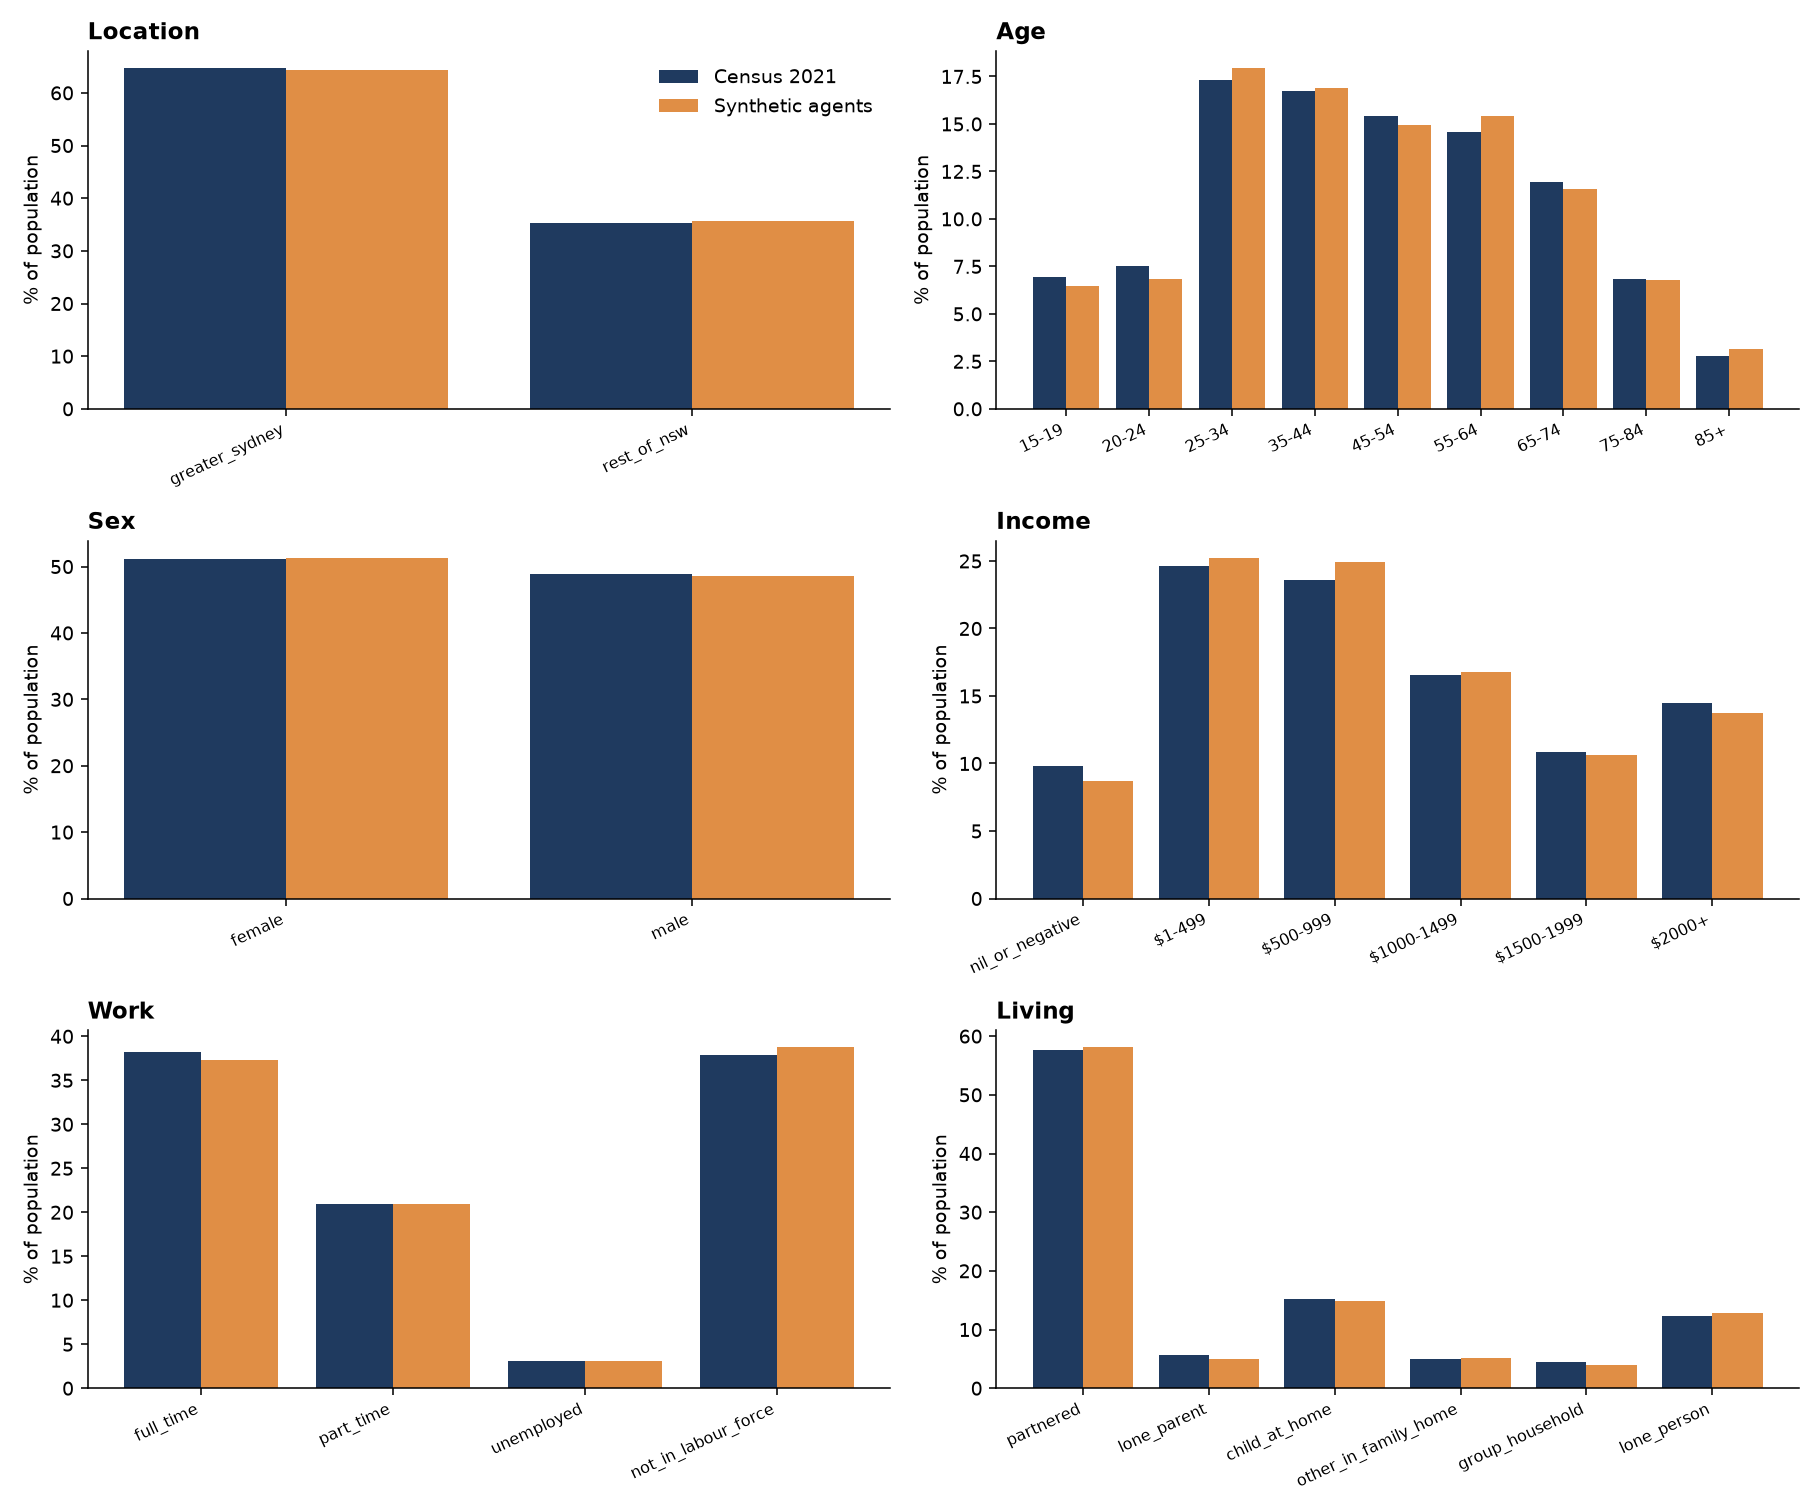

In [7]:
from IPython.display import Image
path = validate.plot_marginals(marginals, ROOT / 'outputs' / 'validation' / 'marginals.png', source_label=SOURCE_LABEL)
Image(str(path))

## 5. A look at the relationships
Full-time workers should rarely have nil income, and adults living with their parents should mostly have low incomes.

In [8]:
pd.crosstab(agents.age, agents.work, normalize='index').round(2)

work,full_time,not_in_labour_force,part_time,unemployed
age,,,,
15-19,0.09,0.50,0.36,0.05
20-24,0.36,0.19,0.36,0.09
25-34,0.55,0.16,0.25,0.04
35-44,0.52,0.21,0.24,0.03
45-54,0.54,0.23,0.19,0.03
55-64,0.41,0.34,0.22,0.02
65-74,0.09,0.81,0.10,0.00
75-84,0.01,0.96,0.02,0.00
85+,0.02,0.98,0.00,0.00


In [9]:
pd.crosstab(agents.work, agents.income, normalize='index').round(2)[CORE_ATTRIBUTES['income']]

income,nil_or_negative,$1-499,$500-999,$1000-1499,$1500-1999,$2000+
work,,,,,,
full_time,0.00,0.02,0.18,0.28,0.20,0.32
not_in_labour_force,0.19,0.44,0.26,0.06,0.02,0.02
part_time,0.01,0.30,0.36,0.18,0.10,0.05
unemployed,0.26,0.39,0.18,0.07,0.07,0.03


In [10]:
pd.crosstab(agents.living, agents.income, normalize='index').round(2)[CORE_ATTRIBUTES['income']]

income,nil_or_negative,$1-499,$500-999,$1000-1499,$1500-1999,$2000+
living,,,,,,
child_at_home,0.24,0.36,0.17,0.12,0.08,0.03
group_household,0.05,0.22,0.37,0.19,0.08,0.09
lone_parent,0.02,0.36,0.28,0.17,0.12,0.06
lone_person,0.06,0.23,0.33,0.15,0.10,0.12
other_in_family_home,0.05,0.31,0.34,0.24,0.05,0.02
partnered,0.07,0.22,0.23,0.18,0.12,0.19


## 6. Save

In [11]:
out = ROOT / 'data' / 'processed' / 'agents_layer_a.csv'
agents.to_csv(out, index=False)
print(out.relative_to(ROOT))

data\processed\agents_layer_a.csv
